# Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_quiz05
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [2]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [3]:
def download_input_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

  return img_gray

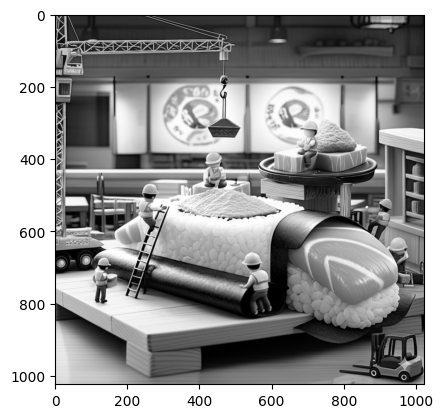

In [4]:
file_id = '1WRLpWrhsJgguvdAdFNcdGZdc_3NrTmjq'
download_url = f'https://drive.google.com/uc?export=download&id={file_id}'
img_gray = download_input_data(download_url)

plt.imshow(img_gray, cmap='gray')
plt.axis('on')
plt.show()

# Questions
1. Reproduce `lab1_question3_2.jpg` using the input image. Display the output image and its absolute difference map compared to the target.
Note: An exact match is not required.

2. Reproduce `lab1_question3_3.jpg` using the input image. Display the output image and its absolute difference map compared to the target.
Note: An exact match is not required.



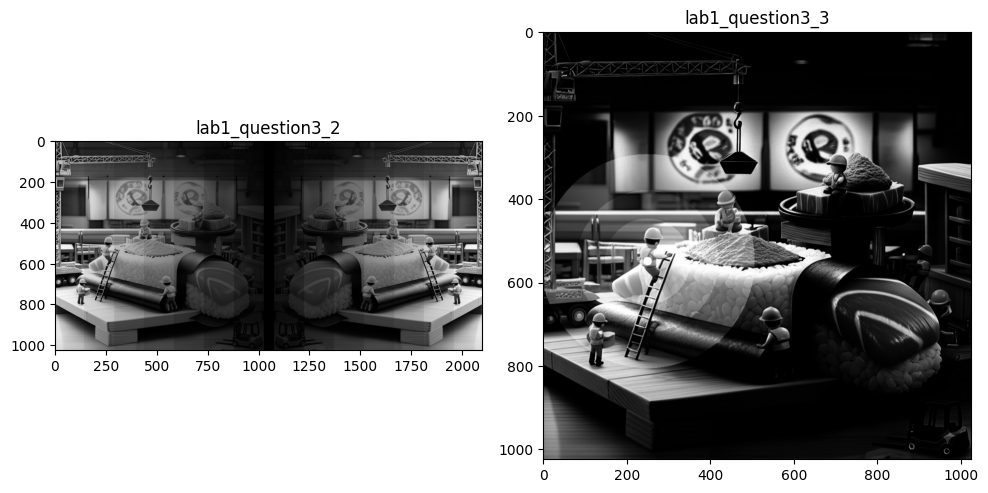

In [15]:
# download link for `lab1_question3_2.jpg` and `lab1_question3_3.jpg`
img_32_url = "https://drive.google.com/uc?export=download&id=1LuezxJ3RzGPrNRBdqUoDykAfcwk3nvgR"
img_33_url = "https://drive.google.com/uc?export=download&id=1T5qeJaTi7_myoB717mXxB-NQX9n4bgNf"

# DOWNLOAD images
img_32 = download_input_data(img_32_url)
img_33 = download_input_data(img_33_url)

# Display images side by side
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_32, cmap='gray')
plt.title("lab1_question3_2")
plt.axis('on')

plt.subplot(1,2,2)
plt.imshow(img_33, cmap='gray')
plt.title("lab1_question3_3")
plt.axis('on')

plt.tight_layout()
plt.show()

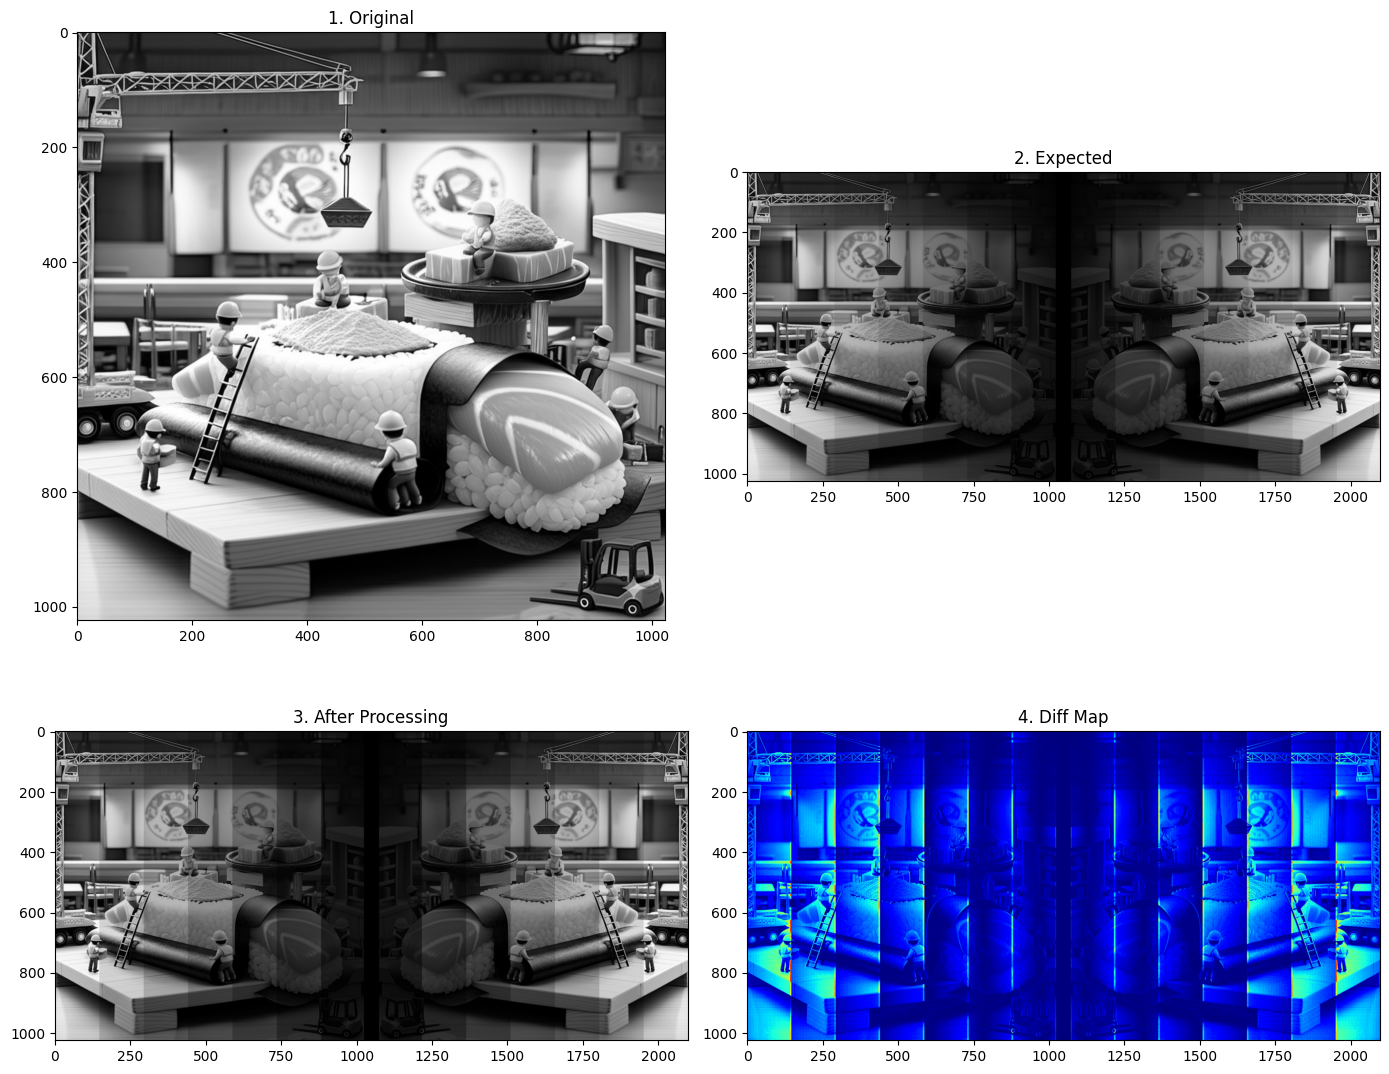

In [16]:
h, w = img_gray.shape

num_bands = 7
band_values = np.linspace(1.0, 0.15, num_bands)

band_width = int(np.ceil(w / num_bands))
gradient_line = np.repeat(band_values, band_width)[:w]
gradient_mask = np.tile(gradient_line, (h, 1))

img_darkened = img_gray * gradient_mask
img_darkened = np.clip(img_darkened, 0, 255).astype(np.uint8)

border_width = 50
border_line = np.zeros((h, border_width), dtype=np.uint8)

img_flipped = np.fliplr(img_darkened)
img_concat = np.hstack((img_darkened, border_line, img_flipped))

img_expected = img_32.copy()

if len(img_expected.shape) == 3:
    img_expected = cv.cvtColor(img_expected, cv.COLOR_BGR2GRAY)

h_min = min(img_concat.shape[0], img_expected.shape[0])
w_min = min(img_concat.shape[1], img_expected.shape[1])

img_concat_resized = cv.resize(img_concat, (w_min, h_min))
img_expected_resized = cv.resize(img_expected, (w_min, h_min))

diff_map = np.abs(
    img_concat_resized.astype(np.int16) - img_expected_resized.astype(np.int16)
).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Display results
axes[0, 0].imshow(img_gray, cmap="gray")
axes[0, 0].set_title("1. Original")
axes[0, 0].axis("on")

axes[0, 1].imshow(img_expected_resized, cmap="gray")
axes[0, 1].set_title("2. Expected")
axes[0, 1].axis("on")

axes[1, 0].imshow(img_concat_resized, cmap="gray")
axes[1, 0].set_title("3. After Processing")
axes[1, 0].axis("on")

axes[1, 1].imshow(diff_map, cmap="jet")
axes[1, 1].set_title("4. Diff Map")
axes[1, 1].axis("on")

plt.tight_layout()
plt.show()

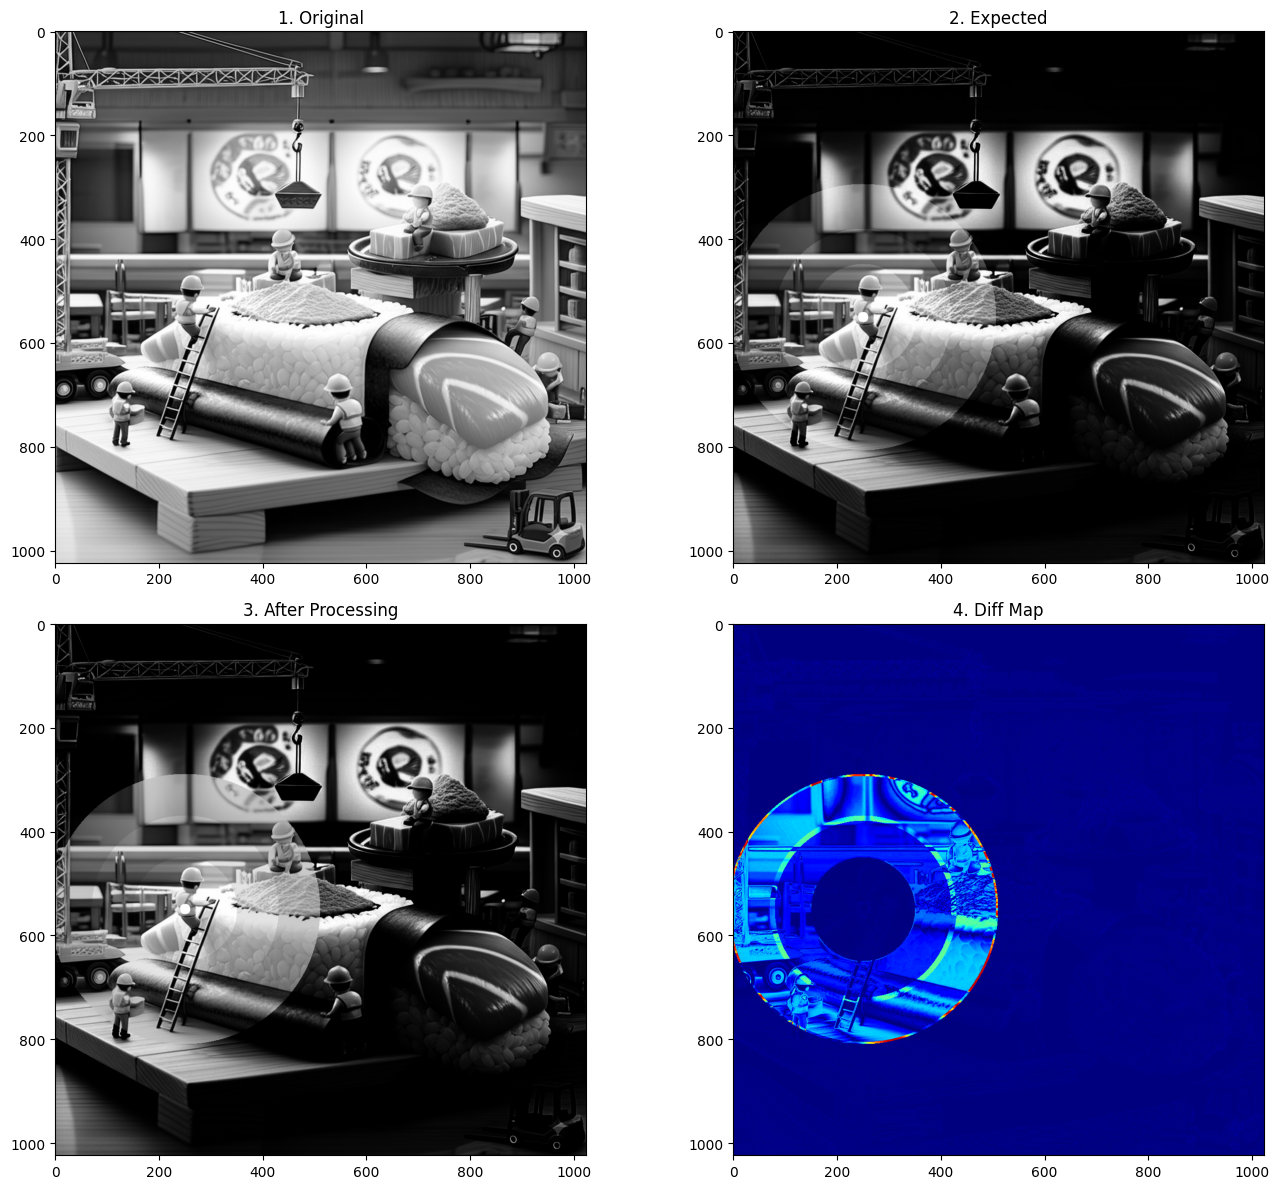

In [56]:
h, w = img_gray.shape
img_expected_resized = cv.resize(img_33, (w, h))

y_indices, x_indices = np.indices((h, w))
center_x, center_y = 250, 550
distance = np.sqrt((x_indices - center_x) ** 2 + (y_indices - center_y) ** 2)

v1 = 10
v2 = 100
v3 = 180
v4 = 260

conditions = [
    (distance > v1) & (distance <= v2),
    (distance > v2) & (distance <= v3),
    (distance > v3) & (distance <= v4),
]
choices = [1.0, 0.90, 0.80]
vignette_effect = np.select(conditions, choices, default=1.0)

img_temp = img_gray.astype(np.float32) * vignette_effect
img_temp = np.where(distance <= v1, 255, img_temp)
img_result = np.clip(img_temp, 0, 255).astype(np.uint8)

outside_mask = distance > v4
img_result_f = img_result.astype(np.float32)

gamma = 5.0

outside = img_result_f[outside_mask] / 255.0
outside_gamma = np.power(outside, gamma)
outside_gamma = outside_gamma * 255.0

img_result_f[outside_mask] = outside_gamma

img_result = np.clip(img_result_f, 0, 255).astype(np.uint8)
outside_mask = distance > v4

diff_map = cv.absdiff(img_result, img_expected_resized)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Display results
axes[0, 0].imshow(img_gray, cmap="gray")
axes[0, 0].set_title("1. Original")
axes[0, 0].axis("on")

axes[0, 1].imshow(img_expected_resized, cmap="gray")
axes[0, 1].set_title("2. Expected")
axes[0, 1].axis("on")

axes[1, 0].imshow(img_result, cmap="gray")
axes[1, 0].set_title("3. After Processing")
axes[1, 0].axis("on")

axes[1, 1].imshow(diff_map, cmap="jet")
axes[1, 1].set_title("4. Diff Map")
axes[1, 1].axis("on")

plt.tight_layout()
plt.show()